# 01 · Data EDA  _(owner: M1)_

Explore MedAESQA, MTSamples, PLABA, MedQuAD, and a Synthea sample; build the FHIR flattener; curate the ~50-example gold set with M5.

In [8]:
import pandas as pd

df = pd.read_csv("../data/mtsamples.csv")

df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [9]:
df.shape

(4999, 6)

In [10]:
df.columns.tolist()

['Unnamed: 0',
 'description',
 'medical_specialty',
 'sample_name',
 'transcription',
 'keywords']

In [ ]:
df.head()

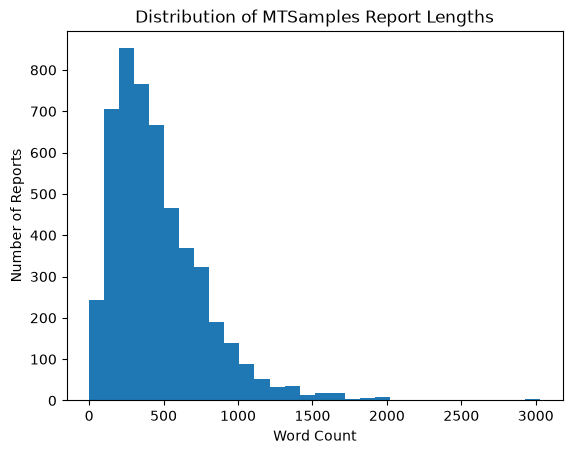

In [13]:
import matplotlib.pyplot as plt

plt.hist(df["word_count"], bins=30)
plt.xlabel("Word Count")
plt.ylabel("Number of Reports")
plt.title("Distribution of MTSamples Report Lengths")
plt.show()

In [15]:
df.isnull().sum()

Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
word_count              0
dtype: int64

In [16]:
df["medical_specialty"].value_counts()

medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

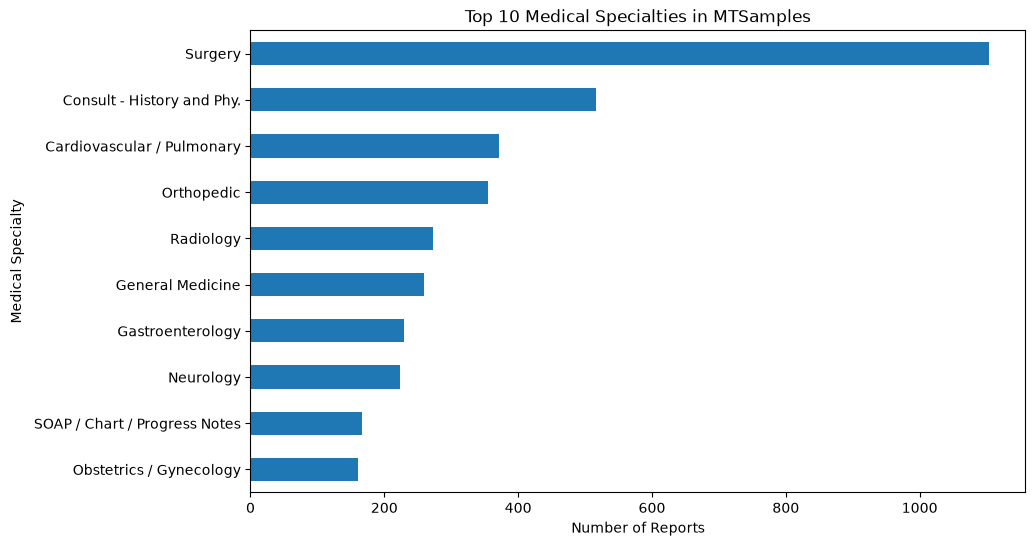

In [17]:
import matplotlib.pyplot as plt

df["medical_specialty"].value_counts().head(10).plot(
    kind="barh",
    figsize=(10, 6)
)

plt.xlabel("Number of Reports")
plt.ylabel("Medical Specialty")
plt.title("Top 10 Medical Specialties in MTSamples")
plt.gca().invert_yaxis()
plt.show()

In [18]:
df["word_count"] = df["transcription"].fillna("").apply(
    lambda text: len(text.split())
)

df["word_count"].describe()

count    4999.000000
mean      462.376275
std       317.585206
min         0.000000
25%       239.000000
50%       397.000000
75%       614.000000
max      3029.000000
Name: word_count, dtype: float64

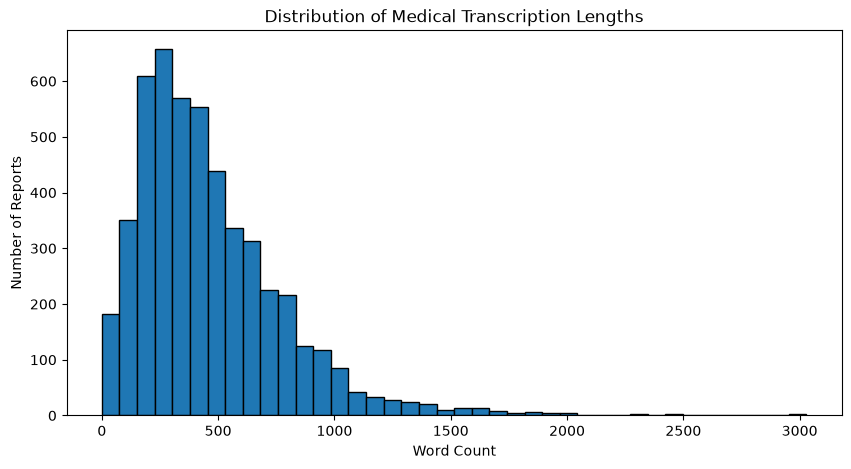

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(df["word_count"], bins=40, edgecolor="black")

plt.xlabel("Word Count")
plt.ylabel("Number of Reports")
plt.title("Distribution of Medical Transcription Lengths")

plt.show()

In [20]:
df.isnull().sum()

Unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
word_count              0
dtype: int64

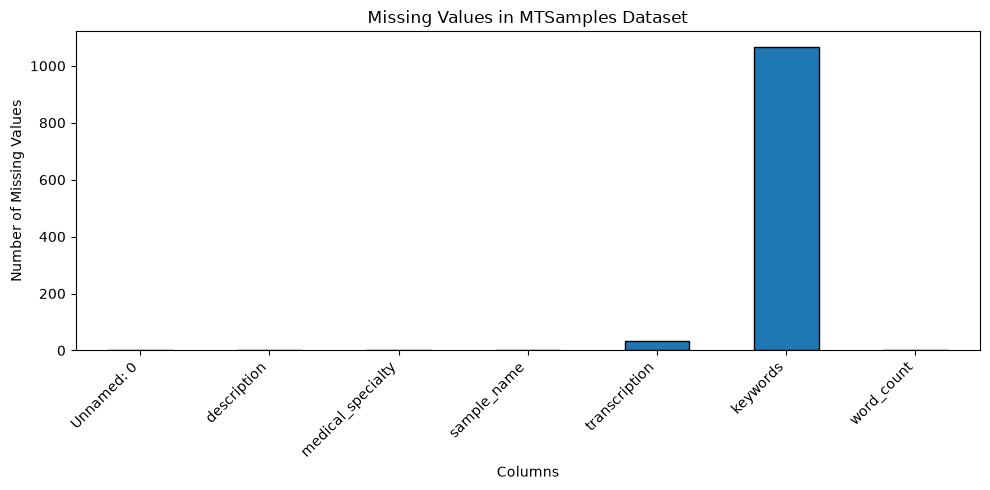

In [21]:
missing = df.isnull().sum()

plt.figure(figsize=(10, 5))

missing.plot(kind="bar", edgecolor="black")

plt.title("Missing Values in MTSamples Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()